# Setup

In [17]:
import os
import glob
import json
from datetime import datetime
import mne
import time
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, LeaveOneGroupOut
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler


# FILE PATHS

# FILE PATHS
BASE_DIR = r"E:\t17"  # The drive folder where all session subdirectories live
JSON_PATH = r'E:\t17\t17.2026.*\brainToText\RedisMat\*.json'

# Updated output names to reflect that these now contain POOLED multi-session data
OUTPUT_CSV = r'C:\Users\bl104\Desktop\pooled_aligned_decoding_table_4.csv'
OUTPUT_NPZ = r'C:\Users\bl104\Desktop\pooled_aligned_decoding_arrays_4.npz'

# MAT KEYS
# Define metadata keys to extract ONLY the text, not the heavy neural data
META_KEYS = ["block_number", "graph_name", "session_name", "binned_neural_redis_clock"]
REDIS_CLOCK_KEY = "binned_neural_redis_clock"
NCTX_KEY = "binned_neural_threshold_crossings"
SPIKE_POWER_KEY = "binned_neural_spike_band_power"

# SLEEP STAGE LABELS

STAGE_MAPPING = {
    "W": 4,
    "R": 3,
    "N1": 2,
    "N2": 1,
    "N3": 0
}

STAGE_NAMES = {
    0: "N3",
    1: "N2",
    2: "N1",
    3: "R",
    4: "W"
}

# Loading + Alignment Helpers

In [ ]:
def get_edf_start_time(edf_path):
    """
    Load EDF metadata and return recording start time.

    Returns:
        datetime
    """

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose=False
    )

    edf_start_dt = raw.info["meas_date"]

    if edf_start_dt.tzinfo is not None:
        edf_start_dt = edf_start_dt.replace(tzinfo=None)

    return edf_start_dt

def load_hypnogram(csv_path, edf_start_dt):
    df = pd.read_csv(
        csv_path, 
        skiprows=4, 
        names=['Event', 'Time', 'Duration'],
        usecols=['Event', 'Time'],
        on_bad_lines='skip'
    )
    
    labels = df['Event'].astype(str).str.strip('" ')
    stages = labels.map(STAGE_MAPPING).fillna(-1).to_numpy()
    
    parsed_times = pd.to_datetime(df['Time'].str.strip('" '), format='%H:%M:%S', errors='coerce')
    
    time_minutes = []
    valid_indices = []
    
    for idx, t_dt in enumerate(parsed_times):
        if pd.isna(t_dt):  
            continue
            
        t = t_dt.time()
        epoch_dt = datetime.combine(edf_start_dt.date(), t)
        
        if epoch_dt < edf_start_dt - timedelta(hours=12):
            epoch_dt += timedelta(days=1)
            
        minutes_from_start = (epoch_dt - edf_start_dt).total_seconds() / 60.0
        time_minutes.append(minutes_from_start)
        valid_indices.append(idx)
        
    return {
        "time_minutes": np.array(time_minutes),
        "stages": stages[valid_indices],
        "labels": labels.to_numpy()[valid_indices]
    }

def load_mat_file(mat_path):
    """
    Load one MAT file.

    Returns:
        dict or None
    """

    try:
        return scipy.io.loadmat(mat_path)

    except Exception as e:
        print(f"⚠️ Failed to load MAT file: {mat_path}")
        print(e)
        return None
    
def datetime_to_edf_minutes(time_dt, edf_start_dt):
    """
    Convert datetime into minutes from EDF start.

    Returns:
        float
    """

    if edf_start_dt.tzinfo is not None:
        edf_start_dt = edf_start_dt.replace(tzinfo=None)

    if time_dt.tzinfo is not None:
        time_dt = time_dt.replace(tzinfo=None)

    return (
        time_dt - edf_start_dt
    ).total_seconds() / 60.0

def extract_mat_metadata(mat_data):
    """
    Extract MAT block metadata.

    Returns:
        dict
    """

    redis_clocks = np.squeeze(
        mat_data[REDIS_CLOCK_KEY]
    )

    return {
        "redis_clocks": redis_clocks,
        "block_id": int(np.squeeze(mat_data["block_number"])),
        "graph_name": str(np.squeeze(mat_data["graph_name"])).upper(),
        "session_name": str(np.squeeze(mat_data["session_name"])).upper(),
        "start_dt": datetime.fromtimestamp(redis_clocks[0] / 1000.0),
        "end_dt": datetime.fromtimestamp(redis_clocks[-1] / 1000.0)
    }

# Build Features Table

In [3]:
def signal_to_features(values, time_minutes, prefix):
    """
    Convert MAT signal into feature columns.

    Returns:
        raw Numpy array of shape (n_time, n_features)   
    """
    values = np.squeeze(values)

    if values.shape[0] != len(time_minutes):
        matching_axes = np.where(
            np.array(values.shape) == len(time_minutes)
        )[0]

        if len(matching_axes) == 0:
            raise ValueError(
                f"No time axis found for {prefix}. "
                f"Signal shape: {values.shape}, "
                f"time length: {len(time_minutes)}"
            )

        values = np.moveaxis(values, matching_axes[0], 0)

    values = values.reshape(len(time_minutes), -1)

    return values

def load_mat_features(mat_directory, edf_start_dt):
    """
    Load ncTX and spike_power from MAT files and align them to EDF time.
    Uses MAT block start/end metadata, matching the visualization notebook logic.
        Returns:
        pd.DataFrame containing time_minutes, metadata columns, and feature columns
        """
    mat_files = sorted(glob.glob(os.path.join(mat_directory, "*.mat")))

    if not mat_files:
        raise FileNotFoundError(f"No MAT files found in: {mat_directory}")

    all_time, all_nctx, all_spike = [], [], []
    all_files, all_blocks, all_graphs = [], [], []

    print("\n⏰ Loading and aligning MAT neural features...")

    for mat_path in mat_files:
        if not os.path.isfile(mat_path):
            continue
            
        mat_data = load_mat_file(mat_path)
        if mat_data is None:
            continue

        metadata = extract_mat_metadata(mat_data)
        start_min = datetime_to_edf_minutes(metadata["start_dt"], edf_start_dt)
        end_min = datetime_to_edf_minutes(metadata["end_dt"], edf_start_dt)

        redis_clocks = metadata["redis_clocks"]
        n_time = len(redis_clocks)
        time_minutes = np.linspace(start_min, end_min, n_time, endpoint=False)

        nctx_vals = signal_to_features(mat_data[NCTX_KEY], time_minutes, "ncTX")
        spike_vals = signal_to_features(mat_data[SPIKE_POWER_KEY], time_minutes, "spike_power")

        all_time.append(time_minutes)
        all_nctx.append(nctx_vals)
        all_spike.append(spike_vals)
        
        file_name = os.path.basename(mat_path)
        all_files.extend([file_name] * n_time)
        all_blocks.extend([metadata['block_id']] * n_time)
        all_graphs.extend([metadata['graph_name']] * n_time)
        
        print(f"  ✅ B.{metadata['block_id']} | {start_min:.2f} → {end_min:.2f} min | {n_time} samples")

    if not all_time:
        raise ValueError("No MAT features were successfully loaded.")

    flat_time = np.concatenate(all_time)
    flat_nctx = np.concatenate(all_nctx, axis=0)
    flat_spike = np.concatenate(all_spike, axis=0)

    df_dict = {
        "time_minutes": flat_time,
        "mat_file": all_files,
        "block_id": all_blocks,
        "graph_name": all_graphs
    }
    
    for col_idx in range(flat_nctx.shape[1]):
        df_dict[f"ncTX_{col_idx+1}"] = flat_nctx[:, col_idx]
    for col_idx in range(flat_spike.shape[1]):
        df_dict[f"spike_power_{col_idx+1}"] = flat_spike[:, col_idx]

    out_df = pd.DataFrame(df_dict).sort_values("time_minutes").reset_index(drop=True)
    
    del all_time, all_nctx, all_spike, df_dict
    
    return out_df

def make_decoding_table(signal_df, hypnogram):
    """
    Blazing fast vectorized version of decoding table creation.
    Replaces the 450-million-operation loop with a single .groupby() sweep.
    """
    feature_columns = [
        col for col in signal_df.columns
        if col.startswith("ncTX") or col.startswith("spike_power")
    ]

    print("🧮 Vectorizing time-bin alignments...")

    epoch_indices = np.floor(signal_df["time_minutes"].to_numpy() / 0.5).astype(int)
    
    signal_df = signal_df.copy()
    signal_df["epoch_idx"] = epoch_indices

    max_epoch = len(hypnogram["stages"]) - 1
    valid_mask = (signal_df["epoch_idx"] >= 0) & (signal_df["epoch_idx"] <= max_epoch)
    clean_signal = signal_df[valid_mask]

    if len(clean_signal) == 0:
        raise ValueError("No overlap found between neural data timestamps and hypnogram bins.")

    print("📊 Computing medians across neural channels instantly...")
    grouped_medians = clean_signal.groupby("epoch_idx")[feature_columns].median()
    
    # We grab the first block ID that appears in each 30-second window.
    grouped_blocks = clean_signal.groupby("epoch_idx")["block_id"].first()

    # 1. Turn the hypnogram dictionary directly into a DataFrame
    hypno_df = pd.DataFrame({
        "sleep_stage_num": hypnogram["stages"],
        "sleep_stage_label": hypnogram["labels"]
    })
    
    # 2. Filter out invalid stages (-1) and calculate the minute windows
    hypno_df = hypno_df[hypno_df["sleep_stage_num"] >= 0].copy()
    hypno_df["start_min"] = hypno_df.index * 0.5
    hypno_df["end_min"] = (hypno_df.index + 1) * 0.5
    
    # 3. Smash them together! Only keeps epochs where we have BOTH hypno and neural data
    decoding_table = hypno_df.join(grouped_medians, how="inner").join(grouped_blocks, how="inner")
    
    # Clean up the index so it looks nice
    decoding_table = decoding_table.reset_index(drop=True)
    
    print(f"🧩 Created {len(decoding_table)} decoding samples.")
    return decoding_table

def make_X_y(decoding_table):
    """
    Make X and y for sleep-stage decoding, dropping any corrupted/NaN rows.
    """
    if "sleep_stage_num" not in decoding_table.columns:
        raise ValueError("decoding_table has no sleep_stage_num column.")

    # Find neural columns
    feature_columns = [col for col in decoding_table.columns if col.startswith(("ncTX", "spike_power"))]

    # Drop NaNs in one clean sweep across targets and features
    clean_df = decoding_table.dropna(subset=feature_columns + ["sleep_stage_num"])

    if clean_df.empty:
        raise ValueError("No clean decoding samples found after dropping NaNs.")

    # Extract clean arrays
    X = clean_df[feature_columns].to_numpy()
    y = clean_df["sleep_stage_num"].astype(int).to_numpy()

    return X, y, feature_columns, clean_df

# Decoding

In [10]:
def decode_data(X, y, groups=None, cv_strategy=None, model='logistic', norm='auto', return_decoder=False):
    """
    The Master Decoder. Encapsulates GroupKFold, StratifiedKFold, and TimeSeriesSplit.
    Dynamically tracks tested samples to support chronological validation seamlessly.
    """
    # 1. Setup Model
    if model == 'logistic':
        clf = LogisticRegression(max_iter=1000, class_weight='balanced', n_jobs=-1)
    elif model == 'gnb':
        clf = GaussianNB(priors=[0.5, 0.5])
    else:
        raise ValueError(f"Unknown model: '{model}'. Choose 'logistic' or 'gnb'.")
    
    # 2. Setup Pipeline
    # 2. Setup Pipeline (Import scalers at the top of your notebook or right here)
    if norm == 'auto' or norm == 'standard':
        scaler = StandardScaler()
    elif norm == 'minmax_0_1':
        scaler = MinMaxScaler(feature_range=(0, 1))
    elif norm == 'minmax_-1_1':
        scaler = MinMaxScaler(feature_range=(-1, 1))
    elif norm is None or norm == 'none':
        scaler = None
    else:
        raise ValueError(f"Unknown norm strategy: '{norm}'")

    # Build the pipeline based on your choice above
    if scaler is not None:
        decoder = Pipeline([('scaler', scaler), ('decoder', clf)])
    else:
        decoder = Pipeline([('decoder', clf)])

    # 3. Handle Default Strategy (LOSO)
    if cv_strategy is None:
        if groups is not None:
            cv_strategy = LeaveOneGroupOut()
        else:
            raise ValueError("You must provide either a 'cv_strategy' or a 'groups' array.")

    # 4. Dynamic Tracking (Supports TimeSeries Split elegantly!)
    actual_y_tested = []
    predicted_y = []
    predicted_proba = []

    # 5. The Cross-Validation Loop
    # (Using enumerable fold tracking just like your original code)
    for fold, (train_idx, test_idx) in enumerate(cv_strategy.split(X, y, groups=groups)):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        
        # Train and Predict
        decoder.fit(X_train, y_train)
        preds = decoder.predict(X_test)
        
        # Safely map multi-stage probabilities based on present classes
        fold_proba = decoder.predict_proba(X_test)
        fold_classes = decoder.named_steps['decoder'].classes_
        
        # Construct a clean probability matrix for this fold's test set
        n_classes = len(np.unique(y))
        safe_fold_proba = np.zeros((len(y_test), n_classes))
        for j, cls in enumerate(fold_classes):
            safe_fold_proba[:, int(cls)] = fold_proba[:, j]
            
        # Collect results dynamically
        actual_y_tested.extend(y_test)
        predicted_y.extend(preds)
        predicted_proba.extend(safe_fold_proba)
        
        # Print out fold metrics exactly like your original scripts
        fold_acc = accuracy_score(y_test, preds)
        print(f"  🔹 Fold {fold+1} | Out-of-Fold Acc: {fold_acc*100:.2f}%")

    # Convert collections cleanly back to numpy arrays
    actual_y_tested = np.array(actual_y_tested)
    predicted_y = np.array(predicted_y)
    predicted_proba = np.array(predicted_proba)

    # 6. Global Return Logic
    if return_decoder:
        print(f"🧠 Training final global {model} model on 100% of data...")
        decoder.fit(X, y)
        return actual_y_tested, predicted_y, predicted_proba, decoder
    else:
        return actual_y_tested, predicted_y, predicted_proba

def plot_confusion_matrix(y, y_pred, decoder_type=""):
    """
    Plot normalized confusion matrix with auto-detecting labels for Binary vs Multiclass.
    """
    from sklearn.metrics import accuracy_score, confusion_matrix
    import matplotlib.pyplot as plt
    import numpy as np
    import textwrap 

    # 1. AUTO-DETECT BINARY VS MULTICLASS
    unique_in_data = np.unique(np.concatenate([y, y_pred]))
    
    if max(unique_in_data) <= 1:
        # If the highest label is 1, we are doing Awake (0) vs Asleep (1)
        labels_dict = {0: "Wake", 1: "Sleep"}
    else:
        # Fallback to your original 5-stage dictionary if it's multiclass
        labels_dict = STAGE_NAMES 

    # Extract the correct classes and labels based on the active dictionary
    classes = np.array(sorted(list(labels_dict.keys())))
    tick_labels = [labels_dict[int(cls)] for cls in classes]
    
    acc = accuracy_score(y, y_pred)

    conf = confusion_matrix(
        y,
        y_pred,
        labels=classes,
        normalize='true'
    )

    plt.figure(figsize=(5.5, 5.5))
    plt.imshow(conf, origin='lower', cmap='viridis')

    plt.xlabel('Predicted', fontsize=10)
    plt.ylabel('True', fontsize=10)
    plt.xticks(np.arange(len(classes)), tick_labels)
    plt.yticks(np.arange(len(classes)), tick_labels)

    # Automatically grab session count if groups_pool exists
    n_sessions = len(np.unique(groups_pool)) if 'groups_pool' in globals() else 15

    raw_title = f"{decoder_type} | {n_sessions} Sessions | Accuracy = {acc*100:.2f}%"
    wrapped_title = "\n".join(textwrap.wrap(raw_title, width=45))
    plt.title(wrapped_title, fontsize=10, pad=15)

    for i in range(conf.shape[0]):
        for j in range(conf.shape[1]):
            plt.text(
                j, i,
                f'{conf[i, j]*100:.1f}%',
                ha='center',
                va='center',
                color='white' if conf[i, j] < 0.5 else 'black',
                fontsize=10
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

def print_predictions(y, y_pred, y_proba):
    """
    Print trial-by-trial predictions.
    """

    classes = np.array([0, 1, 2, 3, 4])

    for i in range(len(y)):

        true = int(y[i])
        pred = int(y_pred[i])
        probs = y_proba[i]

        pred_idx = np.where(classes == pred)[0][0]
        prob_pred = float(probs[pred_idx])

        probs_str = ", ".join([
            f"{STAGE_NAMES[int(cls)]}: {probs[j]:.2f}"
            for j, cls in enumerate(classes)
        ])

        print(
            f"True: {STAGE_NAMES[true]}, "
            f"Pred: {STAGE_NAMES[pred]}, "
            f"Prob(pred): {prob_pred:.2f}, "
            f"Probs: [{probs_str}]"
        )

# Create Numpy Array

In [5]:
# =================================================================
# PHASE 1: Pre-Filter and Validate Sessions Upfront
# =================================================================
session_directories = sorted(glob.glob(os.path.join(BASE_DIR, "t17.2026.*")))
print(f"📂 Scanning {len(session_directories)} directories for valid data structures...")

valid_sessions = []

for s_dir in session_directories:
    if not os.path.isdir(s_dir):
        continue
        
    folder_name = os.path.basename(s_dir)
    beacon_dir = os.path.join(s_dir, "Beacon_data")
    mat_dir = os.path.join(s_dir, "brainToText", "RedisMat")
    
    if not (os.path.exists(beacon_dir) and os.path.exists(mat_dir)):
        continue
        
    edf_matches = glob.glob(os.path.join(beacon_dir, "*.edf"))
    csv_matches = glob.glob(os.path.join(beacon_dir, "*.csv"))
    mat_matches = glob.glob(os.path.join(mat_dir, "*.mat"))
    
    if edf_matches and csv_matches and mat_matches:
        valid_sessions.append({
            "folder_name": folder_name,
            "edf_path": edf_matches[0],
            "hypno_path": csv_matches[0],
            "mat_dir": mat_dir,
            "mat_files": sorted(mat_matches)  # Cache the file list so we don't scan disk again!
        })

print(f"\n✨ Verification Complete! Found {len(valid_sessions)} fully valid sessions ready for compute.")
print("-" * 50)
print("📋 Sessions scheduled for processing:")
for i, sess in enumerate(valid_sessions):
    print(f"  ✔️ {i+1}. {sess['folder_name']}")
print("-" * 50)


# =================================================================
# PHASE 2: Execute Processing on Verified Sessions Only (CORRECTED)
# =================================================================
X_global, y_global, groups_global = [], [], []
session_names_pool, block_types_pool, block_ids_pool = [], [], []

print("\n" + "="*60)
print(f"🚀 STARTING COMPUTATION ENGINE")
print("="*60)

for idx, sess in enumerate(valid_sessions):
    folder_name = sess["folder_name"]
    clean_session_name = folder_name.split('_')[0]
    print(f"\n⚙️ Processing [{idx + 1}/{len(valid_sessions)}]: {folder_name}...")
    
    try:
        # ⚡ OPTIMIZATION: Instant Block Metadata Mapping (Fixed meta_dict Bug)
        block_metadata_map = {}
        for mat_file in sess["mat_files"]:
            mat_meta = scipy.io.loadmat(mat_file, variable_names=META_KEYS) 
            
            try:
                # Extracts cleanly from helper dictionary
                meta_dict = extract_mat_metadata(mat_meta)
                b_num = meta_dict["block_id"]
                block_metadata_map[b_num] = meta_dict.get("graph_name", "UNKNOWN_GRAPH")
            except Exception as e:
                print(f"      ⚠️ Warning: Could not parse block array in {os.path.basename(mat_file)}")

        # --- Heavy Compute Steps ---
        t0 = time.time()
        edf_start_dt = get_edf_start_time(sess["edf_path"])
        hypnogram = load_hypnogram(sess["hypno_path"])
        print(f"  ⏱️ Step 1 (Metadata) Took: {time.time() - t0:.2f} s")
        
        t0 = time.time()
        signal_df = load_mat_features(sess["mat_dir"], edf_start_dt)
        print(f"  ⏱️ Step 2 (MAT Features) Took: {time.time() - t0:.2f} s")
        
        t0 = time.time()
        decoding_table = make_decoding_table(signal_df, hypnogram)
        print(f"  ⏱️ Step 3 (Time-Windowing) Took: {time.time() - t0:.2f} s")
        
        # 🚀 Use clean_df here so lengths perfectly match y_sess!
        X_sess, y_sess, feature_cols, clean_df = make_X_y(decoding_table)
        
        # Guard clause against empty arrays passing down
        if X_sess.shape[0] == 0:
            print(f"  ⚠️ Warning: Session {clean_session_name} yielded 0 samples. Skipping.")
            continue

        # --- Appending to Global Arrays ---
        X_global.append(X_sess)
        y_global.append(y_sess)
        groups_global.append(np.full(len(y_sess), idx)) 
        
        # 🚀 Vectorized Metadata Injection mapped strictly to clean_df
        graph_labels = clean_df['block_id'].astype(int).map(block_metadata_map).fillna("UNKNOWN_BLOCK").values
        session_names_pool.extend([clean_session_name] * len(y_sess))
        block_types_pool.extend(graph_labels)
        block_ids_pool.extend(clean_df['block_id'].astype(int).values)
        
        print(f"✅ Successfully Processed & Tagged: {clean_session_name}")
        
        # Memory wipe
        del signal_df, decoding_table, clean_df, X_sess, y_sess
        
    except Exception as e:
        print(f"❌ Critical error occurred while processing {folder_name}: {e}")
        import traceback
        traceback.print_exc()
        continue


# =================================================================
# PHASE 3: Compile Global Dataset
# =================================================================
if not X_global:
    raise ValueError("No sessions were successfully processed into arrays.")

# High-speed C-level concatenation
X_pool = np.concatenate(X_global, axis=0)
y_pool = np.concatenate(y_global, axis=0)
groups_pool = np.concatenate(groups_global, axis=0)

session_names_arr = np.array(session_names_pool, dtype=object)
block_types_arr = np.array(block_types_pool, dtype=object)
block_ids_arr = np.array(block_ids_pool, dtype=int)

# Overwrite archive safely with all tracking info (Fixed missing block_ids parameter)
np.savez_compressed(
    OUTPUT_NPZ, 
    X=X_pool, 
    y=y_pool, 
    groups=groups_pool,
    session_names=session_names_arr,
    block_types=block_types_arr,
    block_ids=block_ids_arr
)

print("\n" + "="*50)
print(f"💾 Combined dataset compiled and saved to {OUTPUT_NPZ}")
print(f"Total Pooled Samples across all days: {X_pool.shape[0]}")
print("🔑 Saved Keys: ['X', 'y', 'groups', 'session_names', 'block_types', 'block_ids']")
print("="*50 + "\n")

📂 Scanning 30 directories for valid data structures...

✨ Verification Complete! Found 16 fully valid sessions ready for compute.
--------------------------------------------------
📋 Sessions scheduled for processing:
  ✔️ 1. t17.2026.01.20_gesture-sweep
  ✔️ 2. t17.2026.02.02_EEG-BRANDless-four-choice
  ✔️ 3. t17.2026.02.11_EEG-NS5-recording
  ✔️ 4. t17.2026.02.17_speech-sweep-OL
  ✔️ 5. t17.2026.02.18_wizard-of-oz-UI
  ✔️ 6. t17.2026.02.25_gesture-sweep
  ✔️ 7. t17.2026.02.27_wizard-of-oz-UI
  ✔️ 8. t17.2026.03.09_wizard-of-Oz-UI
  ✔️ 9. t17.2026.03.11_comm-gesture-change
  ✔️ 10. t17.2026.03.18_wizard-of-oz-UI
  ✔️ 11. t17.2026.03.23_communication-interface
  ✔️ 12. t17.2026.03.25_UI-communication
  ✔️ 13. t17.2026.04.29_refactored-online
  ✔️ 14. t17.2026.05.27_sliding-window
  ✔️ 15. t17.2026.06.04_mini-gesture-sweep-communication
  ✔️ 16. t17.2026.06.10_six-gesture-UI
--------------------------------------------------

🚀 STARTING COMPUTATION ENGINE

⚙️ Processing [1/16]: t17.2026

# Create Model and Confusion Matrix

  🔹 Fold 1 | Out-of-Fold Acc: 68.75%
  🔹 Fold 2 | Out-of-Fold Acc: 29.70%
  🔹 Fold 3 | Out-of-Fold Acc: 57.14%
  🔹 Fold 4 | Out-of-Fold Acc: 82.76%
  🔹 Fold 5 | Out-of-Fold Acc: 27.85%
  🔹 Fold 6 | Out-of-Fold Acc: 91.67%
  🔹 Fold 7 | Out-of-Fold Acc: 79.00%
  🔹 Fold 8 | Out-of-Fold Acc: 84.04%
  🔹 Fold 9 | Out-of-Fold Acc: 95.88%
  🔹 Fold 10 | Out-of-Fold Acc: 84.97%
  🔹 Fold 11 | Out-of-Fold Acc: 0.00%
  🔹 Fold 12 | Out-of-Fold Acc: 0.00%
  🔹 Fold 13 | Out-of-Fold Acc: 74.29%
  🔹 Fold 14 | Out-of-Fold Acc: 100.00%
  🔹 Fold 15 | Out-of-Fold Acc: 99.51%
  🔹 Fold 16 | Out-of-Fold Acc: 93.33%
🧠 Training final global gnb model on 100% of data...

🎯 Plotting Global Combined Confusion Matrix...


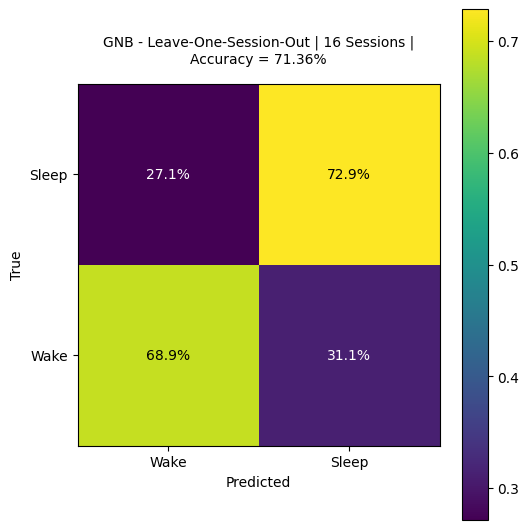

In [14]:
# 1. Load the brand-new dataset into your variable name
decode_model = np.load(OUTPUT_NPZ, allow_pickle=True)

# 2. Extract the arrays directly out of your loaded file variable
X_pool = decode_model['X']
y_pool = decode_model['y']
groups_pool = decode_model['groups']

# 3. Convert sleep labels to binary (4 = Awake (0), everything else = Asleep (1))
y_pool_binary = np.where(y_pool == 4, 0, 1)

# 4. Run your actual model training function (decode_data)
y_test_pool_2, y_pred_pool_2, y_proba_pool_2, decoder_model_2 = decode_data(
    X_pool, 
    y_pool_binary, 
    groups=groups_pool, 
    model='gnb', 
    norm='minmax_-1_1',
    return_decoder=True
)

print("\n🎯 Plotting Global Combined Confusion Matrix...")
plot_confusion_matrix(y_test_pool_2, y_pred_pool_2, decoder_type="GNB - Leave-One-Session-Out")

In [18]:
# 1. Print the clean metrics
print(f"🎯 Out-of-Fold Accuracy: {accuracy_score(y_test_pool_2, y_pred_pool_2) * 100:.2f}%")
print("\n📊 Detailed Classification Report:")
print(classification_report(y_test_pool_2, y_pred_pool_2))

# 2. Extract importance scores and feature names for the heatmap
importance_scores = np.abs(decoder_model_2.named_steps['decoder'].theta_[0] - decoder_model_2.named_steps['decoder'].theta_[1])

num_channels = X_pool.shape[1] // 2  
feature_cols = [f"ncTX_{ch}" for ch in range(1, num_channels + 1)] + [f"spike_power_{ch}" for ch in range(1, num_channels + 1)]

🎯 Out-of-Fold Accuracy: 71.36%

📊 Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.69      0.65      1020
           1       0.79      0.73      0.76      1669

    accuracy                           0.71      2689
   macro avg       0.70      0.71      0.70      2689
weighted avg       0.72      0.71      0.72      2689



# Visualization & Analysis

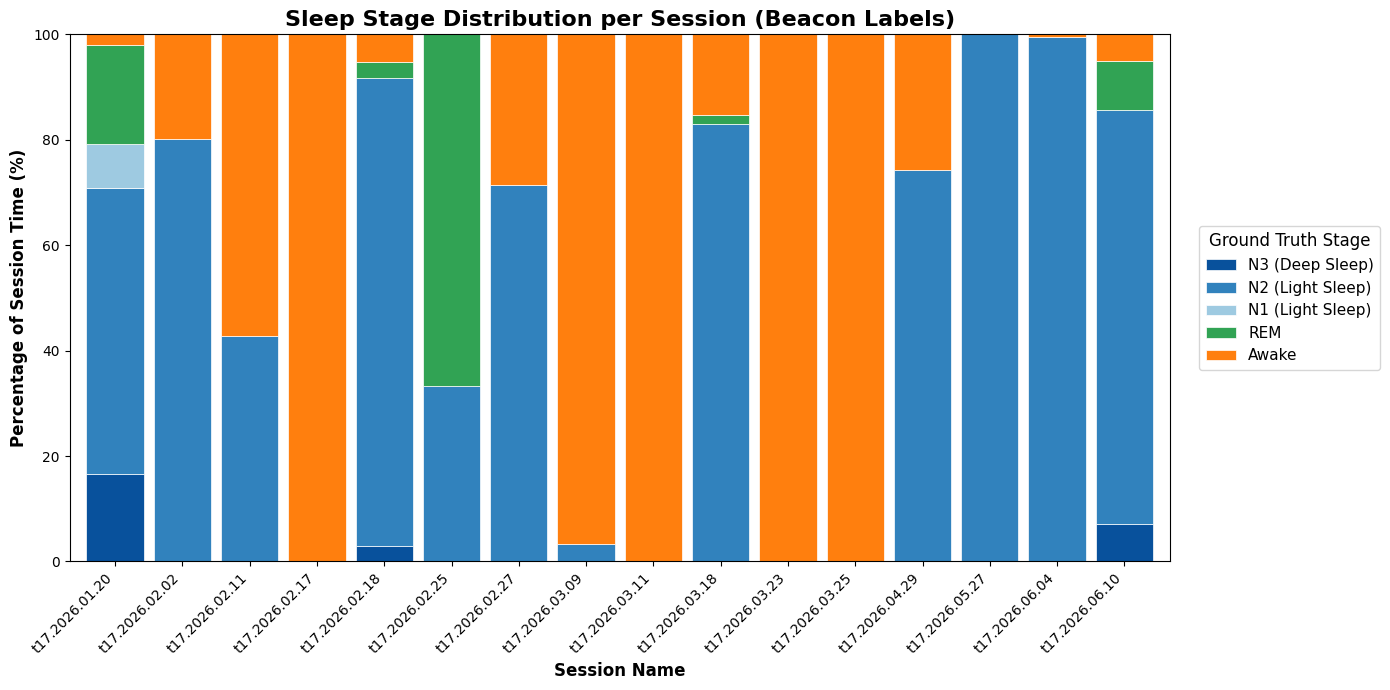

In [56]:
# =====================================================================
# STACKED BAR GRAPH: True Sleep Stage Distribution per Session
# =====================================================================

# 1. Create a DataFrame from your true pooled data
df_true_sleep = pd.DataFrame({
    'Session': session_names_arr,
    'True_Stage': y_pool
})

# 2. Map the numeric labels (0-4) to their actual names
stage_mapping = {
    0: 'N3 (Deep Sleep)',
    1: 'N2 (Light Sleep)',
    2: 'N1 (Light Sleep)',
    3: 'REM',
    4: 'Awake'
}
df_true_sleep['Stage_Name'] = df_true_sleep['True_Stage'].map(stage_mapping)

# 3. Calculate the counts of each stage per session, then convert to percentages
stage_counts = df_true_sleep.groupby(['Session', 'Stage_Name']).size().unstack(fill_value=0)
stage_percentages = stage_counts.div(stage_counts.sum(axis=1), axis=0) * 100

# 4. Enforce a specific stacking order (Deep sleep at the bottom, Awake at the top)
order = ['N3 (Deep Sleep)', 'N2 (Light Sleep)', 'N1 (Light Sleep)', 'REM', 'Awake']
# Ensure all columns exist just in case a stage is completely missing
for col in order:
    if col not in stage_percentages:
        stage_percentages[col] = 0.0
stage_percentages = stage_percentages[order]

# 5. Plot the Stacked Bar Graph
# Colors: Dark Blue -> Light Blue -> Green -> Bright Orange
colors = ['#08519c', '#3182bd', '#9ecae1', '#31a354', '#ff7f0e']

fig, ax = plt.subplots(figsize=(14, 7))
stage_percentages.plot(kind='bar', stacked=True, color=colors, ax=ax, width=0.85, edgecolor='white', linewidth=0.5)

# Formatting
ax.set_title("Sleep Stage Distribution per Session (Beacon Labels)", fontsize=16, fontweight='bold')
ax.set_xlabel("Session Name", fontsize=12, fontweight='bold')
ax.set_ylabel("Percentage of Session Time (%)", fontsize=12, fontweight='bold')
ax.set_ylim(0, 100)

plt.xticks(rotation=45, ha='right', fontsize=10)

# Move the legend outside the plot area
ax.legend(title="Ground Truth Stage", bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=11, title_fontsize=12)

plt.tight_layout()
plt.show()

📂 Scanning 20 JSON files...
📊 Loaded 44 unique calibration entries into the master map.
Sample keys in master map: [('t17.2026.01.07', 5), ('t17.2026.01.07', 6), ('t17.2026.01.12', 1)]

🧠 Loading NPZ arrays...

🔗 Matching NPZ blocks to JSON accuracies...
✅ Successfully matched 18 blocks for plotting!


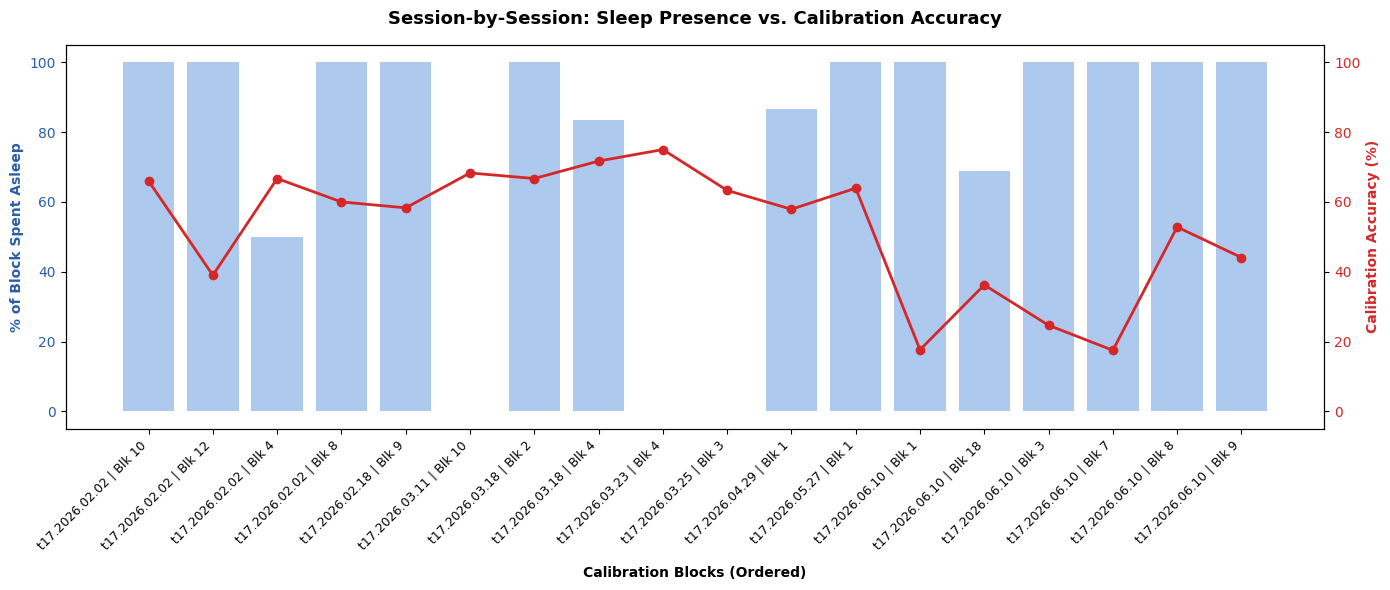

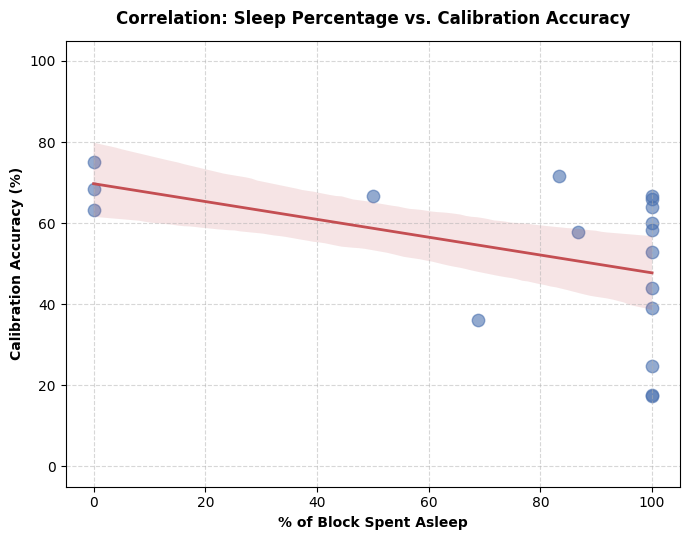

In [ ]:
# =====================================================================
# 1. LOAD ALL CALIBRATIONS INTO A MASTER MAP (DIRECT INNER JSON LOOKUP)
# =====================================================================
calibration_map = {}
json_files = sorted(glob.glob(JSON_PATH))
print(f"📂 Scanning {len(json_files)} JSON files...")

for file in json_files:
    try:
        with open(file, 'r') as jf:
            json_data = json.load(jf)
        
        # Ensure it's a list of records as shown in your example
        if isinstance(json_data, list):
            for item in json_data:
                if 'session_name' in item and 'block_num' in item and 'accuracy' in item:
                    sess = str(item['session_name']).strip()
                    blk = int(item['block_num'])
                    acc = float(item['accuracy'])
                    
                    # Store directly into lookup dictionary
                    calibration_map[(sess, blk)] = acc
                    
    except Exception:
        # Safely ignore empty or corrupt files (like the 0-byte cali_nums.json)
        continue

print(f"📊 Loaded {len(calibration_map)} unique calibration entries into the master map.")

# Print a quick sample to verify keys look clean
if calibration_map:
    print("Sample keys in master map:", list(calibration_map.keys())[:3])

# =====================================================================
# 2. LOAD NPZ & EXTRACT LABELS
# =====================================================================
print("\n🧠 Loading NPZ arrays...")
sleep_data = np.load(OUTPUT_NPZ, allow_pickle=True)

y_labels = sleep_data['y']
session_names = sleep_data['session_names']
block_types = sleep_data['block_types']
block_ids = sleep_data['block_ids']

# =====================================================================
# 3. MATCH ARRAYS TO CALIBRATION MAP
# =====================================================================
df_epochs = pd.DataFrame({
    'Session': session_names,
    'Block_Type': block_types,
    'Stage': y_labels,
    'Block_ID': block_ids
})

# Isolate only the calibration blocks
calib_epochs = df_epochs[df_epochs['Block_Type'].astype(str).str.contains('calib', case=False)]

final_blocks = []
print("\n🔗 Matching NPZ blocks to JSON accuracies...")

for (sess_name, block_id), block_data in calib_epochs.groupby(['Session', 'Block_ID']):
    if len(block_data) < 5:  # Skip tiny/empty fragments
        continue
        
    # Safeguard: Convert bytes strings (b't17...') to regular strings if necessary
    sess_str = sess_name.decode('utf-8') if isinstance(sess_name, bytes) else str(sess_name)
    sess_str = sess_str.strip()
    
    block_key = (sess_str, int(block_id))
    accuracy = calibration_map.get(block_key, None)
    
    if accuracy is not None:
        # Calculate sleep percentage (Stage 4 is Awake, everything else is Asleep)
        sleep_prob = (block_data['Stage'] != 4).mean() * 100
        
        final_blocks.append({
            'Session_Block': f"{sess_str} | Blk {block_id}",
            'Sleep_Percentage': sleep_prob,
            'Accuracy': accuracy  # Kept as raw percentage since your JSON shows 56.7, 66.7
        })
    else:
        print(f"⚠️ No calibration accuracy found for Session {sess_str}, Block {block_id}.")

df_calibration = pd.DataFrame(final_blocks)
print(f"✅ Successfully matched {len(df_calibration)} blocks for plotting!")

# =====================================================================
# 4. PLOT RESULTS
# =====================================================================
if not df_calibration.empty:
    # Sort chronologically by session and block for a clean bar progression
    df_calibration = df_calibration.sort_values('Session_Block').reset_index(drop=True)

    # -----------------------------------------------------------------
    # PLOT A: DUAL-AXIS BAR & LINE CHART
    # -----------------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(14, 6))
    
    # Primary axis: Bars for Sleep Percentage
    ax1.bar(df_calibration.index, df_calibration['Sleep_Percentage'], color='#8bb2e8', alpha=0.7, label='% Asleep')
    ax1.set_xlabel('Calibration Blocks (Ordered)', fontweight='bold', labelpad=10)
    ax1.set_ylabel('% of Block Spent Asleep', color='#2a5da8', fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#2a5da8')
    ax1.set_xticks(df_calibration.index)
    ax1.set_xticklabels(df_calibration['Session_Block'], rotation=45, ha='right', fontsize=9)
    ax1.set_ylim(-5, 105)

    # Secondary axis: Line for Accuracy
    ax2 = ax1.twinx()  
    ax2.plot(df_calibration.index, df_calibration['Accuracy'], color='#d62728', marker='o', linewidth=2, label='Accuracy')
    ax2.set_ylabel('Calibration Accuracy (%)', color='#d62728', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#d62728')
    ax2.set_ylim(-5, 105)

    plt.title("Session-by-Session: Sleep Presence vs. Calibration Accuracy", fontsize=13, fontweight='bold', pad=15)
    fig.tight_layout()
    plt.show()

    print("\n" + "="*50 + "\n") # Visual separator in the console

    # -----------------------------------------------------------------
    # PLOT B: CORRELATION SCATTER PLOT
    # -----------------------------------------------------------------
    plt.figure(figsize=(7, 5.5))
    sns.regplot(data=df_calibration, x='Sleep_Percentage', y='Accuracy', 
                scatter_kws={'alpha':0.6, 's':80, 'color':'#4c72b0'}, 
                line_kws={'color':'#c44e52', 'linewidth':2})
    
    plt.title("Correlation: Sleep Percentage vs. Calibration Accuracy", fontweight='bold', fontsize=12, pad=12)
    plt.xlabel("% of Block Spent Asleep", fontweight='bold')
    plt.ylabel("Calibration Accuracy (%)", fontweight='bold')
    plt.xlim(-5, 105)
    plt.ylim(-5, 105)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

else:
    print("❌ Error: Could not match any blocks. Check format alignment.")

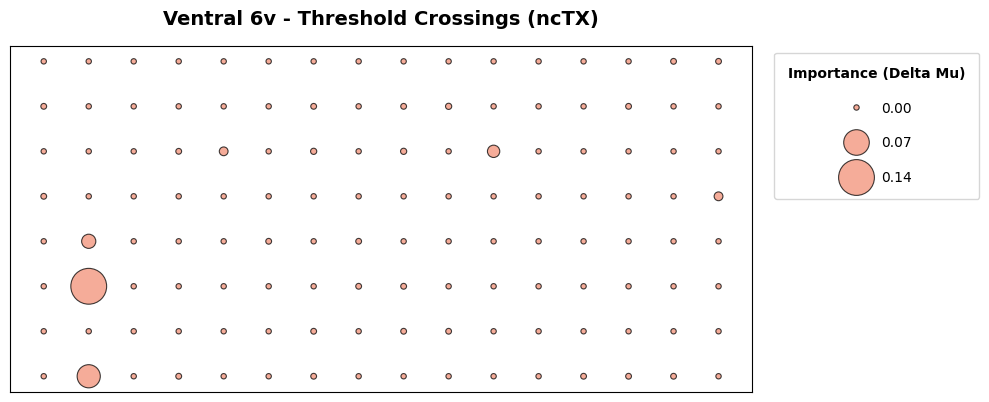

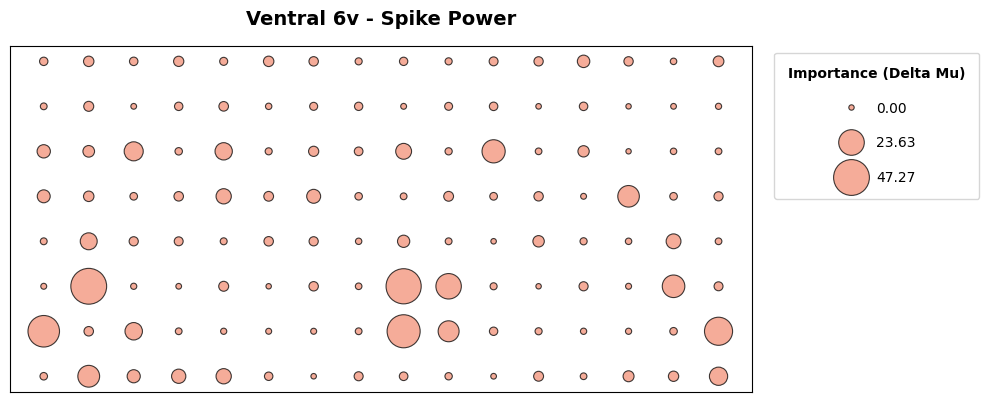

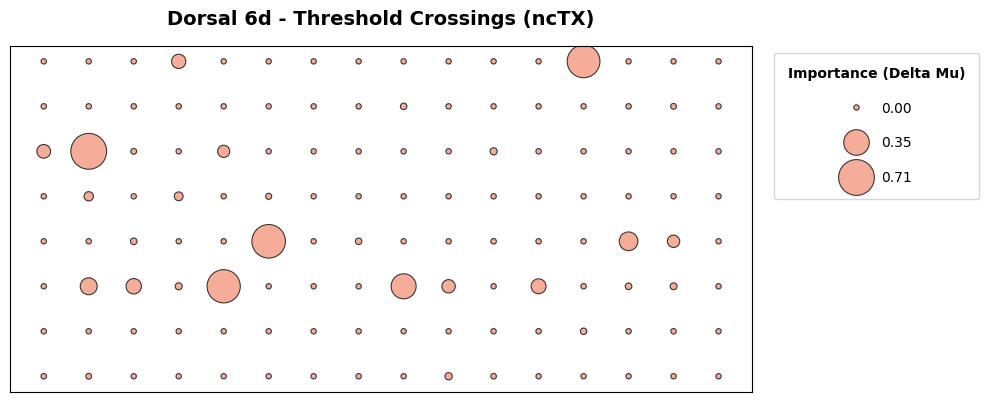

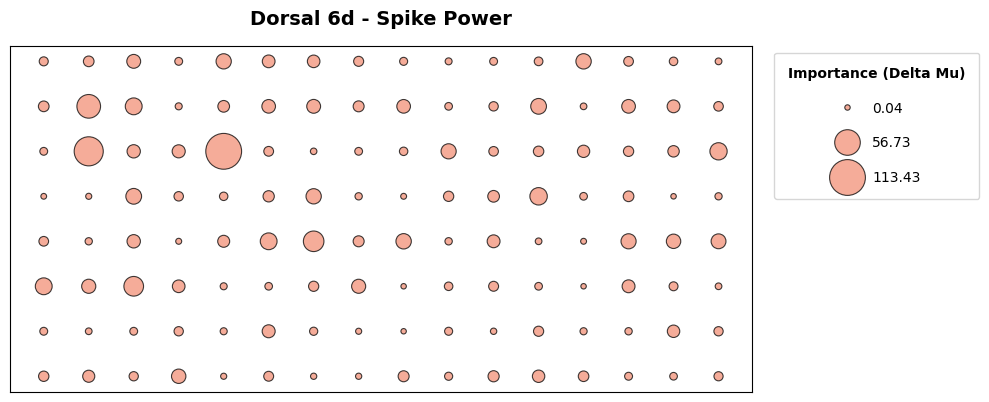

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================
# 1. DEFINE PHYSICAL GRID GEOMETRY (8x16)
# ==========================================
ROWS, COLS = 8, 16

def create_array_grid(channel_importances):
    return np.array(channel_importances).reshape(ROWS, COLS)

# ==========================================
# 2. EXTRACT & SPLIT IMPORTANCES FROM DF
# ==========================================
# Ventral 6v (Channels 1-64)
v_nctx = df_features[(df_features['Type'] == 'ncTX') & (df_features['Channel'] <= 64)]['Importance'].values
v_spike = df_features[(df_features['Type'] == 'spike_power') & (df_features['Channel'] <= 64)]['Importance'].values

# Ventral 6v (Channels 65-128)
v_nctx = df_features[(df_features['Type'] == 'ncTX') & (df_features['Channel'] > 64) & (df_features['Channel'] <= 128)]['Importance'].values
v_spike = df_features[(df_features['Type'] == 'spike_power') & (df_features['Channel'] > 64) & (df_features['Channel'] <= 128)]['Importance'].values

# Dorsal 6d (Channels 129-256)
d_nctx = df_features[(df_features['Type'] == 'ncTX') & (df_features['Channel'] > 128)]['Importance'].values
d_spike = df_features[(df_features['Type'] == 'spike_power') & (df_features['Channel'] > 128)]['Importance'].values

# Dorsal 6d (Channels 129-256)
d_nctx = df_features[(df_features['Type'] == 'ncTX') & (df_features['Channel'] > 128)]['Importance'].values
d_spike = df_features[(df_features['Type'] == 'spike_power') & (df_features['Channel'] > 128)]['Importance'].values

grids = {
    "Ventral 6v - Threshold Crossings (ncTX)": create_array_grid(v_nctx),
    "Ventral 6v - Spike Power": create_array_grid(v_spike),
    "Dorsal 6d - Threshold Crossings (ncTX)": create_array_grid(d_nctx),
    "Dorsal 6d - Spike Power": create_array_grid(d_spike)
}

# ==========================================
# 3. PLOT SPATIAL BUBBLE MATRICES WITH SCALE LEGEND
# ==========================================
for title, grid in grids.items():
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Create coordinates
    y_coords, x_coords = np.indices(grid.shape)
    x_flat = x_coords.flatten()
    y_flat = y_coords.flatten()
    values_flat = grid.flatten()
    
    # --- SAFE 1D PLOT SCALING ---
    max_val = values_flat.max() if values_flat.max() > 0 else 1.0
    scaled_values = values_flat / max_val  # Normalize 0 to 1
    sizes = (scaled_values * 650) + 15     # Custom viewport sizing
    
    # Plot bubbles with uniform fill color
    ax.scatter(
        x_flat, y_flat, 
        s=sizes, 
        color='#f29177',      
        alpha=0.75, 
        edgecolors='black', 
        linewidths=0.8
    )
    
    # --- DYNAMIC SIZE SCALE LEGEND ---
    # Create 3 evenly distributed markers for the raw importance values
    legend_values = np.linspace(values_flat.min(), values_flat.max(), 3)
    
    legend_elements = []
    for val in legend_values:
        # Re-apply the exact scaling math to find the corresponding marker size
        val_scaled = val / max_val
        val_size = (val_scaled * 650) + 15
        
        # Build dummy line markers to display in the legend box
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', label=f'{val:.2f}',
                   markerfacecolor='#f29177', markeredgecolor='black',
                   markeredgewidth=0.8, markersize=np.sqrt(val_size), alpha=0.75)
        )
    
    # Place the size scale legend nicely outside or in the corner
    ax.legend(
        handles=legend_elements, 
        title="Importance (Delta Mu)", 
        title_fontproperties={'weight': 'bold'},
        loc="upper left", 
        bbox_to_anchor=(1.02, 1), # Places legend completely outside the plot boundary
        borderpad=1,
        labelspacing=1.5
    )
    
    # Aesthetics (Matching your exact reference box layout)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    
    # Strip away all edge labels and ticks to leave just a clean structural frame box
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.invert_yaxis()
    ax.set_aspect('equal')
    
    plt.tight_layout()
    plt.show()

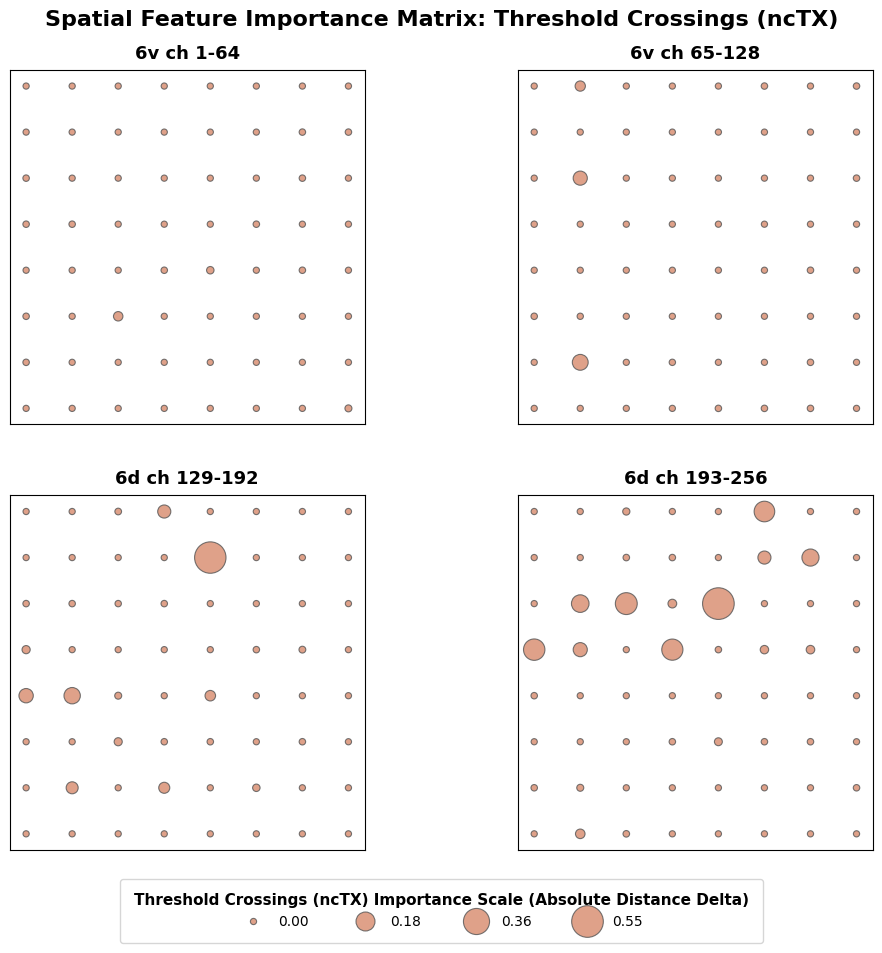

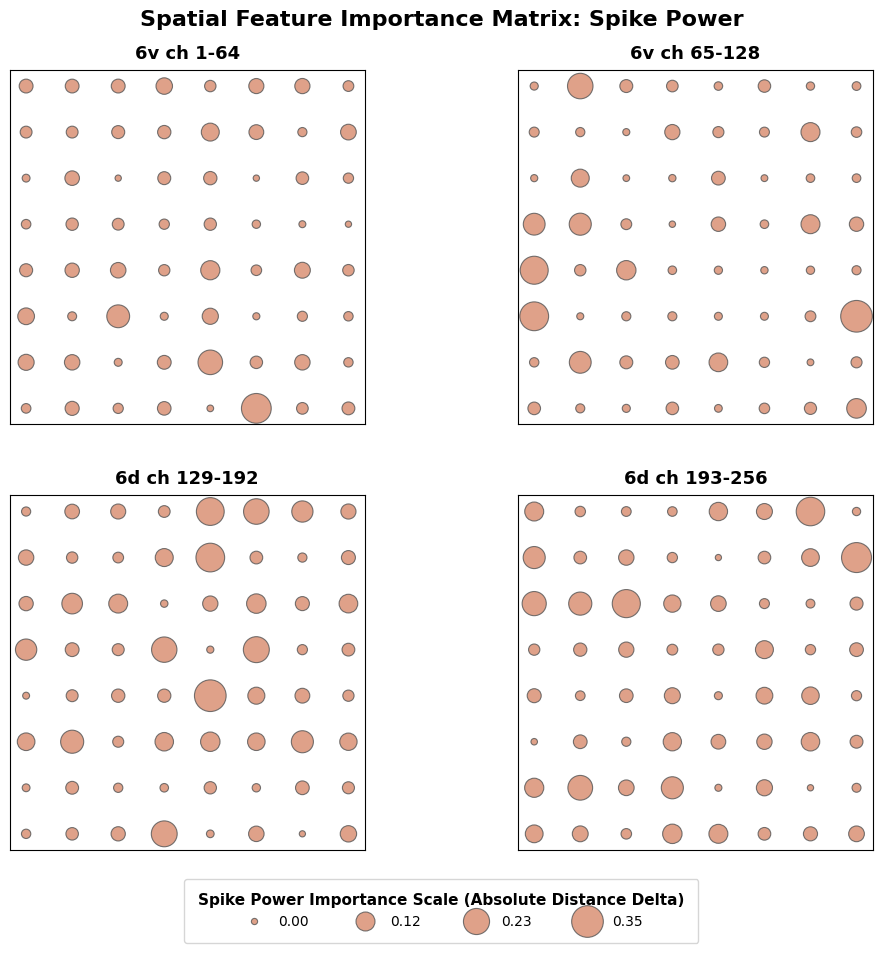

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================
# 0. BUILD DF_FEATURES FROM THE RECENT RUN
# ==========================================
num_channels = len(importance_scores) // 2
channels = list(range(1, num_channels + 1)) + list(range(1, num_channels + 1))
types = ['ncTX'] * num_channels + ['spike_power'] * num_channels

df_features = pd.DataFrame({
    'Feature': feature_cols,
    'Type': types,
    'Channel': channels,
    'Importance': importance_scores
})

ROWS, COLS = 8, 8

def create_array_grid(channel_importances):
    return np.array(channel_importances).reshape(ROWS, COLS)

# ==========================================
# 1. DEFINE UNIFIED PLOTTING FUNCTION
# ==========================================
def plot_feature_grid(feature_type, display_name):
    # Filter arrays using your precise channel boundaries
    v6v_1_64 = df_features[(df_features['Type'] == feature_type) & (df_features['Channel'] <= 64)]['Importance'].values
    v6v_65_128 = df_features[(df_features['Type'] == feature_type) & (df_features['Channel'] > 64) & (df_features['Channel'] <= 128)]['Importance'].values
    
    d6d_129_192 = df_features[(df_features['Type'] == feature_type) & (df_features['Channel'] > 128) & (df_features['Channel'] <= 192)]['Importance'].values
    d6d_193_256 = df_features[(df_features['Type'] == feature_type) & (df_features['Channel'] > 192)]['Importance'].values

    # Corrected panel definitions with the right mathematical sub-labels
    panels = [
        {"title": "6v ch 1-64", "grid": create_array_grid(v6v_1_64)},
        {"title": "6v ch 65-128", "grid": create_array_grid(v6v_65_128)},
        {"title": "6d ch 129-192", "grid": create_array_grid(d6d_129_192)},  # 👈 Fixed labeling
        {"title": "6d ch 193-256", "grid": create_array_grid(d6d_193_256)}   # 👈 Fixed labeling
    ]

    # Find limits for this specific feature map to maximize bubble contrast
    all_vals = np.concatenate([p["grid"].flatten() for p in panels])
    global_min, global_max = all_vals.min(), all_vals.max()
    global_range = global_max - global_min if (global_max - global_min) > 0 else 1.0

    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    fig.suptitle(f"Spatial Feature Importance Matrix: {display_name}", fontsize=16, fontweight='bold', y=0.96)
    axes_flat = axes.flatten()

    for i, panel in enumerate(panels):
        ax = axes_flat[i]
        grid = panel["grid"]
        
        y_coords, x_coords = np.indices(grid.shape)
        x_flat = x_coords.flatten()
        y_flat = y_coords.flatten()
        values_flat = grid.flatten()
        
        scaled_values = (values_flat - global_min) / global_range
        sizes = (scaled_values * 500) + 20  
        
        ax.scatter(
            x_flat, y_flat, 
            s=sizes, 
            color='#d88a6c',      
            alpha=0.8, 
            edgecolors='#545454', 
            linewidths=0.8
        )
        
        ax.set_title(panel["title"], fontsize=13, fontweight='bold', pad=8)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.invert_yaxis()
        ax.set_aspect('equal')

    # Shared scale at bottom
    legend_values = np.linspace(global_min, global_max, 4)
    legend_elements = []

    for val in legend_values:
        val_scaled = (val - global_min) / global_range
        val_size = (val_scaled * 500) + 20
        
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', label=f'{val:.2f}',
                   markerfacecolor='#d88a6c', markeredgecolor='#545454',
                   markeredgewidth=0.8, markersize=np.sqrt(val_size), alpha=0.8)
        )

    fig.legend(
        handles=legend_elements, 
        title=f"{display_name} Importance Scale (Absolute Distance Delta)", 
        title_fontproperties={'weight': 'bold', 'size': 11},
        loc="lower center", 
        ncol=4,
        bbox_to_anchor=(0.5, 0.02),
        borderpad=1,
        columnspacing=3.0
    )

    plt.tight_layout()
    plt.subplots_adjust(top=0.90, bottom=0.12, hspace=0.2, wspace=0.1)
    plt.show()

# ==========================================
# 2. RUN CODES TO GENERATE BOTH PLOTS
# ==========================================
plot_feature_grid(feature_type='ncTX', display_name='Threshold Crossings (ncTX)')
plot_feature_grid(feature_type='spike_power', display_name='Spike Power')